# 04 — Analisis Bivariat dan Multivariat
| | |
|---|---|
| **Nama tim** | Kelompok Alpha |
| **Anggota** | Alfandi Panca Saputra (0110225026) <br>Muhammad Sultan Ridho (0110225099)<br>Dzakwan Abdur Rasyid (0110225036)<br>Mumtaz Abdurrahman (0110225164) |
| **Topik proyek** | Eksplorasi Data Penjualan Bakery |
| **Tanggal** | 9 November 2026 |


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Gunakan path absolut dari Google Drive Anda
BERKAS = '/content/drive/MyDrive/Praktikum EDA/Proyek Tim/Data/processed/bakery_bersih.csv'
df = pd.read_csv(BERKAS)

print(f'{df.shape[0]} baris x {df.shape[1]} kolom')
display(df.head())

232795 baris x 8 kolom


,date,time,ticket_number,article,Quantity,unit_price,total_bayar,bulan
0,2021-01-02,08:38,150040,Baguette,1.0,0.90,0.90,2021-01
1,2021-01-02,08:38,150040,Pain Au Chocolat,3.0,1.20,3.60,2021-01
2,2021-01-02,09:14,150041,Pain Au Chocolat,2.0,1.20,2.40,2021-01
3,2021-01-02,09:14,150041,Pain,1.0,1.15,1.15,2021-01
4,2021-01-02,09:25,150042,Traditional Baguette,5.0,1.20,6.00,2021-01


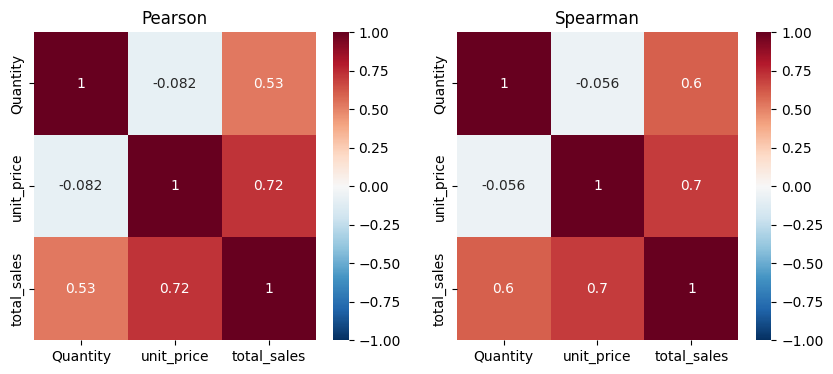

In [8]:
# Hitung total_sales terlebih dahulu jika belum ada di DataFrame
if 'total_sales' not in df.columns:
    df['total_sales'] = df['Quantity'] * df['unit_price']

NUM = ['Quantity', 'unit_price', 'total_sales']
P = df[NUM].corr('pearson')
S = df[NUM].corr('spearman')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(P, ax=axes[0], annot=True, vmin=-1, vmax=1, cmap='RdBu_r'); axes[0].set_title('Pearson')
sns.heatmap(S, ax=axes[1], annot=True, vmin=-1, vmax=1, cmap='RdBu_r'); axes[1].set_title('Spearman')
plt.show()

In [9]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    v = np.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
    print(f"Cramér's V = {v:.3f}")
df['hour'] = pd.to_datetime(df['time']).dt.hour
df['is_weekend'] = pd.to_datetime(df['date']).dt.dayofweek >= 5
cramers_v(df['hour'], df['is_weekend'])

Cramér's V = 0.185


/tmp/ipykernel_1115/3375837869.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['hour'] = pd.to_datetime(df['time']).dt.hour


**Kandidat perancu**:
> Hubungan antara kuantitas pembelian dan harga dapat dipengaruhi oleh *tipe hari (is_weekend)*, karena pola kedatangan pelanggan dan ukuran belanja keluarga biasanya meningkat pada akhir pekan dibandingkan hari kerja.